# Industry Project: Spending a Labeling Budget Wisely with Active Learning (Production-Style)

> **Who is this notebook for?** Beginners who know what a classifier is and need labeled data that **costs money**.
> You do not need the theory from `01_active_learning.ipynb`. Every step is explained in plain English, and almost every line of code has a comment.

---

### How this notebook is different from `01_active_learning.ipynb`

| `01_active_learning.ipynb` | This notebook |
|---|---|
| Implements query strategies on digits / synthetic data | Uses them on **real text** with a **dollar budget** |
| Accuracy vs number of labels | **Cost-vs-quality curve**, "how many dollars to reach the target?" |
| One run per strategy | **Several seeds**, mean and spread |
| Runs until the loop ends | **Stopping criteria**: when is it time to stop paying? |
| No annotators | A real **export batch** for annotators (with pre-annotations and quality-control questions) and the import back |

---

### The business problem

You work at an online community platform. Every new post must be tagged with a **section** so it shows up in the right feed: `cars`, `motorbikes`, `hockey`, `health`, `space` or `politics`.

- There are thousands of untagged posts. Tagging is done by an external **annotation vendor** at **$0.50 per label** (including their QA).
- The budget for this quarter is **$250, i.e. 500 labels**.
- The product team needs a tagger with **macro-F1 ≥ 0.75** before it can go live (macro-F1 because the small sections matter as much as the big ones).
- Like on most real platforms, the sections are **very unequal in size**: politics and hockey posts are common, motorbike posts are rare.

**Your job:** decide **which posts to send to the annotators**, in batches of 25, so that the target is reached as cheaply as possible, and decide **when to stop paying**.

---

### Table of Contents
1. Setup: imports and one central config
2. Get the data: unlabeled pool and a gold evaluation set
3. Features learned from the unlabeled pool
4. The query strategies (random, uncertainty, margin, diversity, hybrid)
5. Simulate labeling rounds with a fixed budget
6. Cost-vs-quality curve: how many dollars to reach the target?
7. What did each strategy choose? (class balance and outliers)
8. Stopping criteria: when to stop paying?
9. Export the next batch for the annotators
10. Import the labels back, with quality control
11. Pitfalls that hurt real active-learning projects
12. Automated tests
13. Summary, exercises and resources

---
## 1. Setup: imports and one central config

In [1]:
# ---- Standard library ----
import json
import logging
import re
import tempfile                  # export files go to a temporary folder (never into the repo)
import time
import warnings
from dataclasses import dataclass, field
from pathlib import Path

# ---- Third-party ----
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.cluster import KMeans
from sklearn.datasets import fetch_20newsgroups
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import cohen_kappa_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("active_learning")


@dataclass(frozen=True)
class Config:
    random_state: int = 42
    cost_per_label_usd: float = 0.50       # vendor price per label
    budget_usd: float = 250.0              # this quarter's budget -> 500 labels
    batch_size: int = 25                   # labels per annotation batch (one "round")
    initial_labels: int = 25               # cold start: first batch is chosen at random
    target_macro_f1: float = 0.75          # go-live requirement
    random_extra_labels: int = 1000        # run RANDOM further than the budget, only to see what it would need
    gold_share: float = 0.35               # share of posts held out as the gold evaluation set
    n_seeds: int = 3                       # repeat every simulation with 3 different cold starts
    min_chars: int = 30                    # empty posts are not sent to annotators
    sections: dict = field(default_factory=lambda: {
        "rec.autos": "cars", "rec.motorcycles": "motorbikes", "rec.sport.hockey": "hockey",
        "sci.med": "health", "sci.space": "space", "talk.politics.guns": "politics"})
    # how many posts of each section the platform sees (skewed, like real traffic)
    section_sizes: dict = field(default_factory=lambda: {
        "politics": 880, "hockey": 900, "space": 700, "cars": 480, "health": 320, "motorbikes": 160})

    @property
    def max_labels(self) -> int:
        return int(self.budget_usd / self.cost_per_label_usd)


CFG = Config()
log.info("scikit-learn %s | budget %s labels", sklearn.__version__, CFG.max_labels)

2026-10-21 17:08:16,517 | INFO | scikit-learn 1.9.0 | budget 500 labels


---
## 2. Get the data: unlabeled pool and a gold evaluation set

We use six newsgroups of the **20 Newsgroups** dataset (cached locally by scikit-learn) as "posts" in six sections. Headers, footers and quotes are removed so the text does not reveal its section.

To mimic real traffic we take a **skewed** sample: many politics and hockey posts, few motorbike posts (about 4.5%). Then:

- **Pool** (65%): the unlabeled posts. In the simulation we know their labels, but the active-learning loop may only **look** at a label after it "paid" for it. This is how active-learning research is usually simulated.
- **Gold set** (35%): a random held-out sample, used only to draw the quality curves.

> **In a real project you do not have a big gold set for free.** You would pay for a **small random validation sample** (e.g. 300 posts = $150) to track progress honestly. Never evaluate on the actively selected labels: they are deliberately the *hardest* posts, so the score would be misleading.

In [2]:
def load_posts() -> pd.DataFrame:
    raw = fetch_20newsgroups(subset="all", categories=list(CFG.sections), remove=("headers", "footers", "quotes"),
                             download_if_missing=False)
    df = pd.DataFrame({"text": [re.sub(r"\s+", " ", t).strip() for t in raw.data],      # tidy whitespace
                       "section": pd.Series(np.array(raw.target_names)[raw.target]).map(CFG.sections)})
    df = df[df["text"].str.len() >= CFG.min_chars].drop_duplicates("text")              # no empty / duplicate posts
    # skewed traffic: keep a fixed number of posts per section
    df = pd.concat([part.sample(n=min(len(part), CFG.section_sizes[name]), random_state=CFG.random_state)
                    for name, part in df.groupby("section")])
    df = df.sample(frac=1, random_state=CFG.random_state).reset_index(drop=True)        # shuffle
    df.insert(0, "post_id", [f"P{i:05d}" for i in range(len(df))])
    return df


posts = load_posts()
n_gold = int(len(posts) * CFG.gold_share)
gold = posts.iloc[:n_gold].reset_index(drop=True)          # random held-out evaluation sample
pool = posts.iloc[n_gold:].reset_index(drop=True)          # the unlabeled pool we can buy labels for

SECTIONS = sorted(CFG.sections.values())
y_pool = pool["section"].map({s: i for i, s in enumerate(SECTIONS)}).to_numpy()   # "hidden" labels of the pool
y_gold = gold["section"].map({s: i for i, s in enumerate(SECTIONS)}).to_numpy()
print(f"Unlabeled pool: {len(pool):,} posts | gold set: {len(gold):,} posts | budget: {CFG.max_labels} labels")
print("Posts per section in the pool:", pool["section"].value_counts().to_dict())

Unlabeled pool: 2,235 posts | gold set: 1,203 posts | budget: 500 labels
Posts per section in the pool: {'politics': 601, 'hockey': 579, 'space': 451, 'cars': 294, 'health': 210, 'motorbikes': 100}


---
## 3. Features learned from the unlabeled pool

Two representations, both learned **without labels** (so using the whole pool is fine):
- **TF-IDF** vectors for the classifier.
- **100-dimensional SVD vectors** (a compressed "topic" summary) to measure **similarity between posts**, which the diversity strategies need.

In [3]:
vectorizer = TfidfVectorizer(sublinear_tf=True, min_df=2, max_df=0.8, stop_words="english")
X_pool = vectorizer.fit_transform(pool["text"])          # fit on the unlabeled pool: no labels involved
X_gold = vectorizer.transform(gold["text"])

embedder = make_pipeline(TruncatedSVD(n_components=100, random_state=CFG.random_state), Normalizer())
E_pool = embedder.fit_transform(X_pool)                  # dense, unit-length vectors -> dot product = similarity
print("TF-IDF:", X_pool.shape, "| embeddings:", E_pool.shape)


def make_classifier() -> LogisticRegression:
    """The model we will train after every batch (fast, good for text)."""
    return LogisticRegression(C=10, solver="saga", max_iter=300, tol=1e-3)

TF-IDF: (2235, 13801) | embeddings: (2235, 100)


---
## 4. The query strategies

Each strategy receives the current model and the indices of still-unlabeled posts, and returns the `batch_size` posts to buy labels for next.

| Strategy | Idea | Typical weakness |
|---|---|---|
| **random** | the honest baseline | wastes labels on easy, redundant posts |
| **least confidence** | posts whose top probability is lowest | can pick many near-duplicates or junk |
| **margin** | smallest gap between the top-2 classes ("the model hesitates between two sections") | same, but usually the best simple choice |
| **diversity** | one post per k-means cluster of the unlabeled pool (covers all topics) | ignores what the model already knows |
| **hybrid** (margin + diversity) | take the 10 × batch most uncertain posts, cluster them into `batch_size` groups, and pick the most uncertain post of each group | a bit more compute |

The **hybrid** is the batch-mode idea behind methods such as modAL's *ranked batch-mode sampling* and BADGE: a batch of 25 should be uncertain **and** different from each other, otherwise you pay 25 times for nearly the same lesson.

In [4]:
def probabilities(model, idx):
    return model.predict_proba(X_pool[idx])


def query_random(model, unlabeled, k, rng):
    return rng.choice(unlabeled, size=k, replace=False)


def query_least_confidence(model, unlabeled, k, rng):
    confidence = probabilities(model, unlabeled).max(axis=1)         # how sure the model is about its top class
    return unlabeled[np.argsort(confidence)[:k]]                      # least sure first


def margin_scores(model, idx):
    p = np.sort(probabilities(model, idx), axis=1)
    return p[:, -1] - p[:, -2]                                        # top-1 minus top-2 probability


def query_margin(model, unlabeled, k, rng):
    return unlabeled[np.argsort(margin_scores(model, unlabeled))[:k]]   # smallest margin first


def query_diversity(model, unlabeled, k, rng, sample_size=1000):
    sample = rng.choice(unlabeled, size=min(sample_size, len(unlabeled)), replace=False)   # subsample for speed
    km = KMeans(n_clusters=k, n_init=1, random_state=int(rng.integers(10**6))).fit(E_pool[sample])
    picks = []
    for c in range(k):                                                # the post closest to each cluster centre
        members = np.flatnonzero(km.labels_ == c)
        d = np.linalg.norm(E_pool[sample[members]] - km.cluster_centers_[c], axis=1)
        picks.append(sample[members[np.argmin(d)]])
    return np.array(picks)


def query_hybrid(model, unlabeled, k, rng, candidate_factor=10):
    margins = margin_scores(model, unlabeled)
    candidates = unlabeled[np.argsort(margins)[: k * candidate_factor]]          # 1. the most uncertain 250
    cand_margin = np.sort(margins)[: k * candidate_factor]
    km = KMeans(n_clusters=k, n_init=1, random_state=int(rng.integers(10**6))).fit(E_pool[candidates])
    picks = [candidates[np.flatnonzero(km.labels_ == c)[np.argmin(cand_margin[km.labels_ == c])]]
             for c in range(k)]                                                  # 2. most uncertain per cluster
    return np.array(picks)


STRATEGIES = {"random": query_random, "least_confidence": query_least_confidence, "margin": query_margin,
              "diversity": query_diversity, "hybrid": query_hybrid}

---
## 5. Simulate labeling rounds with a fixed budget

The loop below is exactly what happens in a real project, except that "send to annotators and wait two days" is replaced by "look up the hidden label":

```
cold start: 25 random posts labeled
repeat until the budget is spent:
    train the model on all labels bought so far
    measure quality (gold set)          <- in real life: a small random validation set
    choose the next 25 posts with the strategy
    buy their labels (pay 25 x $0.50)
```

We also record the model's predictions on a fixed **"stop set"** of 1,000 unlabeled posts after each round; Section 8 uses them for a label-free stopping rule. Every strategy is run with **3 different cold starts** (seeds), because one run can be lucky.

In [5]:
rng_stop = np.random.default_rng(0)
STOP_SET = rng_stop.choice(len(pool), size=1000, replace=False)       # fixed unlabeled posts for stopping rule


def run_active_learning(strategy_name: str, seed: int, max_labels: int = CFG.max_labels):
    """Simulate labeling rounds until the budget is spent. Returns one row per round."""
    rng = np.random.default_rng(seed)
    labeled = rng.choice(len(pool), size=CFG.initial_labels, replace=False)   # cold start (same for all strategies)
    history, prev_stop_pred = [], None
    while True:
        model = make_classifier().fit(X_pool[labeled], y_pool[labeled])      # train on labels bought so far
        stop_pred = model.predict(X_pool[STOP_SET])
        history.append({
            "strategy": strategy_name, "seed": seed, "n_labels": len(labeled),
            "cost_usd": len(labeled) * CFG.cost_per_label_usd,
            "macro_f1": f1_score(y_gold, model.predict(X_gold), average="macro"),
            "n_sections_seen": len(np.unique(y_pool[labeled])),
            "kappa_vs_prev_round": cohen_kappa_score(prev_stop_pred, stop_pred) if prev_stop_pred is not None else np.nan,
        })
        prev_stop_pred = stop_pred
        if len(labeled) + CFG.batch_size > max_labels:                        # budget exhausted
            break
        unlabeled = np.setdiff1d(np.arange(len(pool)), labeled)
        batch = STRATEGIES[strategy_name](model, unlabeled, CFG.batch_size, rng)
        labeled = np.concatenate([labeled, batch])                            # "pay" for the labels
    return pd.DataFrame(history), labeled


t0 = time.perf_counter()
curves, chosen = [], {}
for name in STRATEGIES:
    for seed in range(CFG.n_seeds):
        hist, labeled_idx = run_active_learning(name, seed)
        curves.append(hist)
        chosen[(name, seed)] = labeled_idx
        if name == "random":                                       # how far would random need to go?
            extra, _ = run_active_learning(name, seed, max_labels=CFG.random_extra_labels)
            curves.append(extra[extra["n_labels"] > CFG.max_labels].assign(beyond_budget=True))
    log.info("%-17s done (%.0fs elapsed)", name, time.perf_counter() - t0)
curves = pd.concat(curves, ignore_index=True)
curves["beyond_budget"] = curves["beyond_budget"].fillna(False).astype(bool)
in_budget = curves[~curves["beyond_budget"]]
print(in_budget.groupby(["strategy", "n_labels"])["macro_f1"].mean().unstack(0).iloc[::4].round(3))

2026-10-21 17:09:23,447 | INFO | random            done (31s elapsed)


2026-10-21 17:09:28,321 | INFO | least_confidence  done (36s elapsed)


2026-10-21 17:09:35,475 | INFO | margin            done (43s elapsed)


2026-10-21 17:11:34,011 | INFO | diversity         done (162s elapsed)


2026-10-21 17:12:01,800 | INFO | hybrid            done (189s elapsed)


strategy  diversity  hybrid  least_confidence  margin  random
n_labels                                                     
25            0.226   0.245             0.206   0.296   0.234
125           0.515   0.513             0.545   0.532   0.417
225           0.594   0.633             0.717   0.661   0.550
325           0.646   0.694             0.738   0.709   0.589
425           0.688   0.717             0.745   0.729   0.631


---
## 6. Cost-vs-quality curve: how many dollars to reach the target?

This is the chart the budget owner wants: **x = dollars spent, y = quality**, one line per strategy (mean of 3 seeds, the shaded band shows min-max across seeds), with the go-live target as a horizontal line. The dotted grey line continues **random sampling beyond the budget** (up to 1,000 labels), only to answer "how much would we have to spend without active learning?".

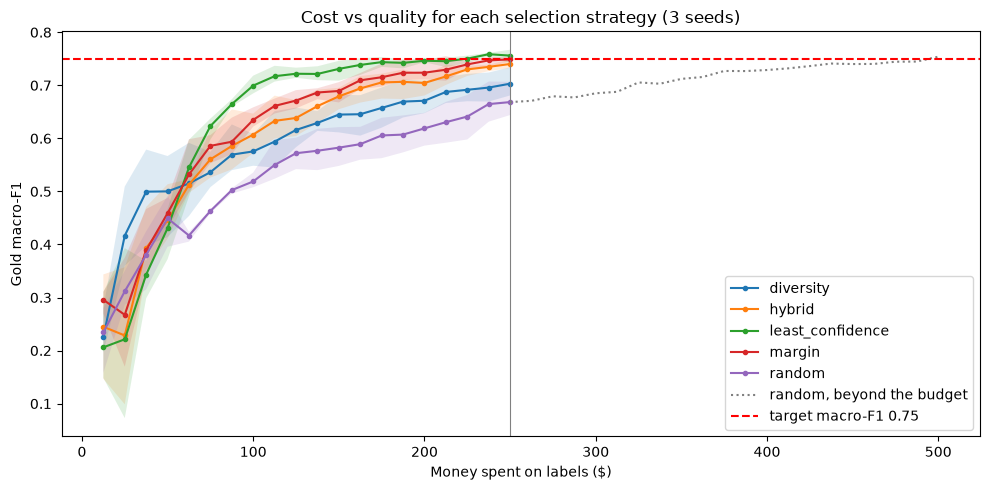

                  usd_to_reach_target  f1_at_$100  f1_at_full_budget  \
strategy                                                               
least_confidence                225.0       0.700              0.756   
margin                            NaN       0.635              0.749   
hybrid                            NaN       0.607              0.740   
diversity                         NaN       0.575              0.703   
random                          500.0       0.519              0.668   

                  saving_vs_random_usd  
strategy                                
least_confidence                 275.0  
margin                             NaN  
hybrid                             NaN  
diversity                          NaN  
random                             0.0  


In [6]:
summary_all = curves.groupby(["strategy", "cost_usd"])["macro_f1"].agg(["mean", "min", "max"]).reset_index()
summary = summary_all[summary_all["cost_usd"] <= CFG.budget_usd]          # inside the budget
fig, ax = plt.subplots(figsize=(10, 5))
for name, part in summary.groupby("strategy"):
    ax.plot(part["cost_usd"], part["mean"], marker=".", label=name)
    ax.fill_between(part["cost_usd"], part["min"], part["max"], alpha=0.15)
beyond = summary_all[(summary_all["strategy"] == "random") & (summary_all["cost_usd"] >= CFG.budget_usd)]
ax.plot(beyond["cost_usd"], beyond["mean"], color="grey", ls=":", label="random, beyond the budget")
ax.axvline(CFG.budget_usd, color="grey", lw=0.8)
ax.axhline(CFG.target_macro_f1, color="red", ls="--", label=f"target macro-F1 {CFG.target_macro_f1}")
ax.set_xlabel("Money spent on labels ($)"); ax.set_ylabel("Gold macro-F1")
ax.set_title("Cost vs quality for each selection strategy (3 seeds)")
ax.legend(); plt.tight_layout(); plt.show()


def dollars_to_target(part: pd.DataFrame) -> float:
    """First spend level at which the MEAN curve reaches the target (NaN if never)."""
    hit = part[part["mean"] >= CFG.target_macro_f1]
    return float(hit["cost_usd"].iloc[0]) if len(hit) else np.nan


budget_table = pd.DataFrame({
    "usd_to_reach_target": summary_all.groupby("strategy").apply(dollars_to_target),
    "f1_at_$100": summary[summary["cost_usd"] == 100].set_index("strategy")["mean"],
    "f1_at_full_budget": summary.groupby("strategy")["mean"].last(),
}).sort_values("f1_at_full_budget", ascending=False)
random_cost = budget_table.loc["random", "usd_to_reach_target"]
budget_table["saving_vs_random_usd"] = random_cost - budget_table["usd_to_reach_target"]
print(budget_table.round(3))

**How to read the result (look at the table, not only the chart):**
- **Every active strategy beats random sampling** at every budget level after the first ~100 labels. At the full budget ($250 = 500 labels), random sampling reaches a macro-F1 of only ~0.67, while the uncertainty strategies reach ~0.74-0.76.
- **Least confidence** is the winner in this run: it reaches the 0.75 target after ~450 labels (~$225). Random sampling needs about **1,000 labels (~$500)** to get there, so active learning roughly **halves the labeling bill**. Margin and the hybrid end just below the target (≈0.75 and ≈0.74); differences of ±0.01 between them are within the seed-to-seed spread (the shaded bands).
- **Pure diversity** is better than random but clearly worse than the uncertainty strategies: it covers the topics, but it does not focus on the posts the model finds hard.
- The hybrid did **not** beat plain margin sampling here. Batch diversity matters most when batches are large compared with the pool (see exercise 1); with batches of 25 the most uncertain posts were already fairly varied.

**Why does active learning help so much here?** Mostly because the sections are **imbalanced**. Random sampling spends most of the budget on the big sections (politics, hockey) and buys only a handful of motorbike posts, so macro-F1 suffers. Uncertainty sampling automatically goes looking for the sections the model is unsure about, which are the small and confusable ones (Section 7).

> **Honest note from building this notebook:** on a *balanced* version of the same six newsgroups, margin sampling was **not** better than random sampling within a 500-label budget. Active learning is not a free lunch: it pays off most with skewed classes, large pools, and a model whose uncertainty is meaningful. Always run the random baseline next to it.

---
## 7. What did each strategy choose? (class balance and outliers)

A classic side effect: uncertainty sampling **does not sample the classes evenly**. It buys many labels from sections that are confusable (e.g. `cars` vs `motorbikes`) and few from easy ones. Let's look at the class mix of the labels each strategy bought, and at the **length** of the chosen posts (very short or very long posts are often "junk" that is uncertain but not useful).

In [7]:
mix_rows = []
for (name, seed), idx in chosen.items():
    if seed != 0:
        continue
    counts = pd.Series(y_pool[idx]).map(dict(enumerate(SECTIONS))).value_counts()
    mix_rows.append({"strategy": name, **counts.to_dict(),
                     "median_chars": int(np.median(pool["text"].str.len().to_numpy()[idx]))})   # typical post length
mix = pd.DataFrame(mix_rows).set_index("strategy").fillna(0)
print(f"Labels bought per section (seed 0, {CFG.max_labels} labels each); pool median length = {int(pool['text'].str.len().median())} chars")
print(mix.astype(int))

Labels bought per section (seed 0, 500 labels each); pool median length = 505 chars
                  hockey  politics  space  cars  health  motorbikes  \
strategy                                                              
random               123       121    100    71      57          28   
least_confidence      92       100     97    88      73          50   
margin                87       105    106    86      73          43   
diversity            140       129     90    61      61          19   
hybrid                87       103    105    85      75          45   

                  median_chars  
strategy                        
random                     509  
least_confidence           312  
margin                     344  
diversity                  964  
hybrid                     365  


Random sampling mirrors the skewed pool: only ~28 of its 500 labels are motorbike posts. The uncertainty-based strategies buy almost **twice as many** motorbike posts and more `cars` / `health` posts (motorbikes vs cars is the classic confusion), which is exactly why their macro-F1 is higher. They also prefer **shorter** posts (median ~310-370 characters vs ~500 in the pool): a short post contains few words the model knows, so it is unsure. Pure diversity does the opposite: it picks long, "typical" posts near cluster centres and even fewer rare-section posts.

Neither behaviour is "wrong", but it has consequences:
- Because the actively chosen labels are **not a random sample**, you cannot use them to estimate accuracy or class frequencies. Keep a separate random validation sample.
- If you later train a **different** model (e.g. a transformer) on these labels, the selection was tailored to the logistic regression and may be less useful for the new model.

---
## 8. Stopping criteria: when to stop paying?

Running until the budget is gone is the simplest rule, but often wasteful. Three practical rules:

1. **Target reached** on the (small, random) validation set: stop as soon as macro-F1 ≥ 0.75.
2. **Plateau**: the validation score improved by less than 0.005 over the last 3 batches.
3. **Stabilising predictions** (Bloodgood & Vijay-Shanker, 2009), which needs **no labels at all**: compare the model's predictions on the fixed unlabeled stop set between consecutive rounds (Cohen's kappa). When the model stops changing its mind (kappa ≥ 0.97 for 3 rounds in a row), new labels are no longer teaching it much.

Below we apply all three to the **margin** strategy (seed 0).

                                                     rule  stop_at_labels  cost_usd  macro_f1_at_stop
                 target reached (needs validation labels)           425.0     212.5             0.755
                        plateau (needs validation labels)           450.0     225.0             0.744
stabilizing predictions, kappa >= 0.95 (no labels needed)           425.0     212.5             0.755
stabilizing predictions, kappa >= 0.97 (no labels needed)             NaN       NaN               NaN
                                         budget exhausted           500.0     250.0             0.749


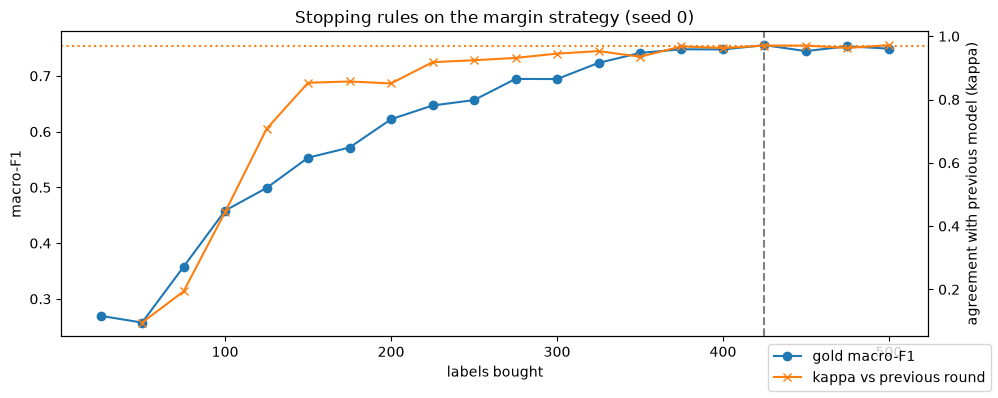

In [8]:
run = curves[(curves["strategy"] == "margin") & (curves["seed"] == 0)].reset_index(drop=True)


def first_round(mask: pd.Series):
    return int(run.loc[mask.idxmax(), "n_labels"]) if mask.any() else None


target_rule = first_round(run["macro_f1"] >= CFG.target_macro_f1)
gain_last3 = run["macro_f1"] - run["macro_f1"].shift(3)
plateau_rule = first_round((gain_last3 < 0.005) & (run["n_labels"] >= 100))


def stabilizing_rule_at(kappa_threshold: float, patience: int = 3):
    """First round after which kappa >= threshold for `patience` consecutive rounds."""
    stable = (run["kappa_vs_prev_round"] >= kappa_threshold).astype(int)
    return first_round(stable.rolling(patience).sum() == patience)


stabilizing_rule = stabilizing_rule_at(0.97)
rules = {"target reached (needs validation labels)": target_rule,
         "plateau (needs validation labels)": plateau_rule,
         "stabilizing predictions, kappa >= 0.95 (no labels needed)": stabilizing_rule_at(0.95),
         "stabilizing predictions, kappa >= 0.97 (no labels needed)": stabilizing_rule,
         "budget exhausted": int(run["n_labels"].max())}
stop_table = pd.DataFrame([{"rule": r, "stop_at_labels": n,
                            "cost_usd": n * CFG.cost_per_label_usd if n else None,
                            "macro_f1_at_stop": float(run.loc[run["n_labels"] == n, "macro_f1"].iloc[0]) if n else None}
                           for r, n in rules.items()])
print(stop_table.round(3).to_string(index=False))

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(run["n_labels"], run["macro_f1"], marker="o", label="gold macro-F1")
ax1.set_xlabel("labels bought"); ax1.set_ylabel("macro-F1")
ax2 = ax1.twinx()
ax2.plot(run["n_labels"], run["kappa_vs_prev_round"], color="tab:orange", marker="x", label="kappa vs previous round")
ax2.axhline(0.97, color="tab:orange", ls=":"); ax2.set_ylabel("agreement with previous model (kappa)")
for n, style in [(target_rule, "--"), (stabilizing_rule, "-.")]:
    if n:
        ax1.axvline(n, color="grey", ls=style)
fig.legend(loc="lower right"); ax1.set_title("Stopping rules on the margin strategy (seed 0)")
plt.tight_layout(); plt.show()

**Interpretation.** Each rule answers a different question. "Target reached" is what the business asked for, but it needs a trustworthy validation set. "Plateau" protects you from paying for tiny gains. "Stabilizing predictions" is attractive because it costs nothing: in this run, with a kappa threshold of 0.95 it stopped at the same point where the target was reached (saving the last ~$37), while the stricter 0.97 threshold never triggered within the budget (`NaN`). So the threshold must be chosen with care, ideally on a past project.

In practice teams combine them: *stop when the target is reached on validation, or when predictions are stable, or when the budget is spent, whichever comes first*, and leave some budget in reserve for **monitoring** labels after launch.

---
## 9. Export the next batch for the annotators

Now the practical part that tutorials skip. The annotation vendor (or your in-house tool such as **Label Studio**, Prodigy, Labelbox, Amazon SageMaker Ground Truth) needs a **file of tasks**. Good batches contain:

- a stable `task_id`, the text, and the **round number** (to trace which model chose it),
- a **pre-annotation** (the model's suggestion): annotators are faster when they confirm or correct a suggestion. *Caveat:* suggestions can bias annotators toward the model's mistakes, so many teams show them only for confident items, or not at all for the uncertain ones,
- a few **gold questions** ("honeypots"): items with known labels mixed in at random to measure each annotator's accuracy,
- the **selection reason** (e.g. margin value), useful for debugging.

We build the next batch from the margin model (seed 0) and export it as **Label Studio-style JSON** and a CSV, into a temporary folder. We only attach a pre-annotation when the model is at least 60% confident.

In [9]:
labeled_so_far = chosen[("margin", 0)]
current_model = make_classifier().fit(X_pool[labeled_so_far], y_pool[labeled_so_far])
unlabeled = np.setdiff1d(np.arange(len(pool)), labeled_so_far)
batch_idx = query_hybrid(current_model, unlabeled, CFG.batch_size, np.random.default_rng(7))

proba = current_model.predict_proba(X_pool[batch_idx])
batch = pd.DataFrame({
    "task_id": pool["post_id"].to_numpy()[batch_idx],
    "text": pool["text"].to_numpy()[batch_idx],
    "suggested_section": np.array(SECTIONS)[proba.argmax(axis=1)],
    "suggestion_confidence": proba.max(axis=1).round(3),
    "margin": margin_scores(current_model, batch_idx).round(3),
    "selection_reason": "hybrid: low margin, diverse",
    "round": len(labeled_so_far) // CFG.batch_size + 1,
    "is_gold_question": False,
})

# Mix in 3 gold questions: items whose label we already know (from earlier, double-checked batches)
gold_idx = np.random.default_rng(1).choice(labeled_so_far, size=3, replace=False)
gold_questions = pd.DataFrame({"task_id": pool["post_id"].to_numpy()[gold_idx], "text": pool["text"].to_numpy()[gold_idx],
                               "suggested_section": None, "suggestion_confidence": None, "margin": None,
                               "selection_reason": "gold question", "round": batch["round"].iloc[0],
                               "is_gold_question": True})
export = pd.concat([batch, gold_questions]).sample(frac=1, random_state=3).reset_index(drop=True)   # shuffle!

# Label Studio import format: one dict per task, "data" = what the annotator sees, optional "predictions"
tasks = []
for _, r in export.iterrows():
    task = {"data": {"task_id": r.task_id, "text": r.text[:2000]},           # truncate very long posts
            "meta": {"round": int(r["round"]), "reason": r.selection_reason}}
    if r.suggested_section and r.suggestion_confidence >= 0.6:               # show suggestions only when confident
        task["predictions"] = [{"model_version": "margin-lr-v1", "score": float(r.suggestion_confidence),
                                "result": [{"from_name": "section", "to_name": "text", "type": "choices",
                                            "value": {"choices": [r.suggested_section]}}]}]
    tasks.append(task)

EXPORT_DIR = Path(tempfile.mkdtemp(prefix="annotation_batch_"))       # real life: a bucket the vendor reads
(EXPORT_DIR / "batch_tasks.json").write_text(json.dumps(tasks, indent=1))
export.drop(columns="is_gold_question").to_csv(EXPORT_DIR / "batch_tasks.csv", index=False)  # vendor must not see the flag
print(f"Exported {len(export)} tasks ({export['is_gold_question'].sum()} gold questions) to {EXPORT_DIR}")
print(f"Tasks with a pre-annotation: {sum('predictions' in t for t in tasks)} / {len(tasks)}")
export[["task_id", "suggested_section", "suggestion_confidence", "margin", "selection_reason"]].head(8)

Exported 28 tasks (3 gold questions) to /tmp/annotation_batch_bltqutdc
Tasks with a pre-annotation: 0 / 28


,task_id,suggested_section,suggestion_confidence,margin,selection_reason
0,P02092,cars,0.265,0.013,"hybrid: low margin, diverse"
1,P02054,cars,0.318,0.007,"hybrid: low margin, diverse"
2,P01692,health,0.225,0.008,"hybrid: low margin, diverse"
3,P02349,None,NaN,NaN,gold question
4,P02634,politics,0.303,0.026,"hybrid: low margin, diverse"
5,P01720,politics,0.286,0.011,"hybrid: low margin, diverse"
6,P01663,space,0.268,0.012,"hybrid: low margin, diverse"
7,P01434,politics,0.217,0.003,"hybrid: low margin, diverse"


Notice that **none** of the 25 selected posts got a pre-annotation: their confidences are all around 0.2-0.3. That is expected, since active learning selects exactly the posts the model is unsure about. Pre-annotations are much more useful for the *random* or *monitoring* part of a labeling budget.

---
## 10. Import the labels back, with quality control

Two days later the vendor returns a file of labels. Before using them:
1. **Check the gold questions.** If the annotator got them wrong, re-label the batch or review it.
2. **Check agreement with the model** on the batch: very low agreement is normal for uncertain items, but **100% agreement** with the pre-annotation is a red flag (the annotator may be clicking "accept" without reading).
3. **Merge** only accepted labels into the training set, keep the raw file for audits.

We simulate an annotator who is right 92% of the time (realistic for a 6-class task).

In [10]:
def simulate_vendor_labels(export: pd.DataFrame, accuracy: float = 0.92, seed: int = 11) -> pd.DataFrame:
    """Stand-in for the vendor: true label with prob `accuracy`, otherwise a random wrong section."""
    rng = np.random.default_rng(seed)
    truth = pool.set_index("post_id").loc[export["task_id"], "section"].to_numpy()
    wrong = np.array([rng.choice([s for s in SECTIONS if s != t]) for t in truth])
    labels = np.where(rng.random(len(truth)) < accuracy, truth, wrong)
    return pd.DataFrame({"task_id": export["task_id"], "label": labels, "annotator": "vendor_A"})


returned = simulate_vendor_labels(export)
merged = export.merge(returned, on="task_id", validate="one_to_one")

gold_check = merged[merged["is_gold_question"]]
known = pool.set_index("post_id").loc[gold_check["task_id"], "section"].to_numpy()
gold_accuracy = (gold_check["label"].to_numpy() == known).mean()
agree_with_model = (merged.loc[~merged["is_gold_question"], "label"] ==
                    merged.loc[~merged["is_gold_question"], "suggested_section"]).mean()

print(f"Gold-question accuracy: {gold_accuracy:.0%}  (accept the batch if >= 2/3 correct)")
print(f"Agreement with the model's suggestion on new items: {agree_with_model:.0%}")
batch_accepted = gold_accuracy >= 2 / 3
new_labels = merged[~merged["is_gold_question"]] if batch_accepted else merged.iloc[0:0]
print(f"Batch accepted: {batch_accepted} -> {len(new_labels)} new labels added to the training set")

Gold-question accuracy: 100%  (accept the batch if >= 2/3 correct)
Agreement with the model's suggestion on new items: 56%
Batch accepted: True -> 25 new labels added to the training set


Three gold questions per batch is a small sample (one mistake already means 67%). Real vendors spread more gold questions over many batches and track each annotator's accuracy over time; for important data, items are labeled by **two annotators** and disagreements go to an expert.

---
## 11. Pitfalls that hurt real active-learning projects

| Pitfall | What happens | Mitigation |
|---|---|---|
| Evaluating on the actively chosen labels | Scores look terrible or meaningless (hardest items only) | Pay for a small **random** validation set |
| Cold start | With 0-25 labels the model's uncertainty is unreliable | Start with a random or diverse batch (we used 25 random) |
| Redundant batches | 25 near-identical uncertain posts | Hybrid uncertainty + diversity (Section 4) |
| Outliers / junk | Uncertainty picks unreadable or off-topic posts | Filter by length / language, allow an "skip / other" label |
| Annotator noise on hard items | Uncertain items are also hard for humans | Gold questions, double labeling, clear guidelines |
| Model change later | Labels chosen for model A are less useful for model B | Keep some random labels in every batch (e.g. 20%) |
| Slow turnaround | Waiting for each batch wastes time | Larger batches, or label random items while the next batch is computed |

---
## 12. Automated tests

In [11]:
def test_budget_is_respected():
    assert in_budget["n_labels"].max() <= CFG.max_labels
    assert in_budget["cost_usd"].max() <= CFG.budget_usd


def test_no_duplicate_purchases():
    """Paying twice for the same item is a classic bug in AL loops."""
    for idx in chosen.values():
        assert len(idx) == len(np.unique(idx))


def test_export_contains_gold_questions_and_no_leak():
    assert export["is_gold_question"].sum() == 3
    assert "is_gold_question" not in pd.read_csv(EXPORT_DIR / "batch_tasks.csv").columns


def test_queries_only_unlabeled_items():
    assert not set(batch_idx) & set(labeled_so_far)


def test_active_beats_random_at_full_budget():
    assert budget_table.loc["margin", "f1_at_full_budget"] >= budget_table.loc["random", "f1_at_full_budget"]


for test_fn in [test_budget_is_respected, test_no_duplicate_purchases, test_export_contains_gold_questions_and_no_leak,
                test_queries_only_unlabeled_items, test_active_beats_random_at_full_budget]:
    test_fn()
    print(f"PASSED  {test_fn.__name__}")

PASSED  test_budget_is_respected


PASSED  test_no_duplicate_purchases
PASSED  test_export_contains_gold_questions_and_no_leak
PASSED  test_queries_only_unlabeled_items
PASSED  test_active_beats_random_at_full_budget


---
## 13. Summary, exercises and resources

| Practice | What we did | Where it is used |
|---|---|---|
| Think in dollars | Cost-vs-quality curve, dollars to reach the target | Planning labeling budgets |
| Baseline strategy | Random sampling, always | Proving active learning is worth the complexity |
| Uncertainty sampling | Least confidence, margin | Text, images, tabular |
| Batch diversity | Hybrid margin + k-means | Batch-mode AL (modAL ranked batch, BADGE) |
| Several seeds | 3 cold starts per strategy | Honest comparisons |
| Stopping rules | Target, plateau, stabilizing predictions | Avoid paying for no gain |
| Annotation export | Label Studio-style JSON + CSV, pre-annotations, gold questions | Working with vendors / labeling tools |
| Label QA | Gold-question accuracy, agreement checks | Any human labeling pipeline |

### Practice exercises
1. Set `batch_size=100` (fewer, bigger batches). How much worse does margin sampling get compared with batches of 25? Is the hybrid more robust?
2. Add a strategy that mixes 80% margin and 20% random items in every batch. How does it compare?
3. Change the stabilizing-predictions threshold to 0.95 and 0.99. How does the stopping point move?
4. Combine with semi-supervised learning: after each round, pseudo-label the most confident posts (see `../03_semi_supervised/02_industry_ticket_labeling_with_few_labels.ipynb`).

### Resources
- Burr Settles, *Active Learning Literature Survey* (the classic overview): https://burrsettles.com/pub/settles.activelearning.pdf
- modAL documentation, *Ranked batch-mode sampling* (uncertainty + diversity in one batch): https://modal-python.readthedocs.io/en/latest/content/examples/ranked_batch_mode.html
- small-text, an active-learning library for text classification (query strategies and stopping criteria): https://github.com/webis-de/small-text
- Robert (Munro) Monarch, *Human-in-the-Loop Machine Learning* (Manning, 2021) and its code: https://github.com/rmunro/pytorch_active_learning
- Bloodgood & Vijay-Shanker (2009), *A Method for Stopping Active Learning Based on Stabilizing Predictions*: https://aclanthology.org/W09-1107/
- Label Studio docs, *Import pre-annotated data*: https://labelstud.io/guide/predictions

### Related notebooks
- Query strategies explained: `01_active_learning.ipynb`
- Learning from unlabeled data instead: `../03_semi_supervised/02_industry_ticket_labeling_with_few_labels.ipynb`
- Text classification basics: `../../07_NLP/03_text_classification.ipynb`